In [1]:
import tensorflow as tf
from tensorflow import keras

2022-02-01 07:03:25.918206: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2022-02-01 07:03:25.918248: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


Note how the dataset has 60,000 instances and each instance is a 28x28 image. Each instance must be flatten for analysis!

In [2]:
fashion_mnist = keras.datasets.fashion_mnist
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

In [3]:
print(f"Train Shape: {X_train_full.shape}. Train Data Type: {X_train_full.dtype}.")

Train Shape: (60000, 28, 28). Train Data Type: uint8.


In [4]:
X_valid, X_train = X_train_full[:5000] / 255.0, X_train_full[5000:] / 255.0
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]

In [5]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "shirt", "Sneaker", "Bag", "Ankle boot"]

In [6]:
class_names[y_train[0]]

'Coat'

## Neural Network Using Sequential API

In [7]:
model = keras.models.Sequential()
model.add(keras.layers.Flatten(input_shape=[28, 28]))
model.add(keras.layers.Dense(300, activation="relu"))
model.add(keras.layers.Dense(100, activation="relu"))
model.add(keras.layers.Dense(10, activation="softmax")) # Used for multicategorical prediction.

2022-02-01 07:03:58.675906: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2022-02-01 07:03:58.675992: W tensorflow/stream_executor/cuda/cuda_driver.cc:269] failed call to cuInit: UNKNOWN ERROR (303)
2022-02-01 07:03:58.676069: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (ColimaDragon): /proc/driver/nvidia/version does not exist


In [8]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 300)               235500    
                                                                 
 dense_1 (Dense)             (None, 100)               30100     
                                                                 
 dense_2 (Dense)             (None, 10)                1010      
                                                                 
Total params: 266,610
Trainable params: 266,610
Non-trainable params: 0
_________________________________________________________________


In [9]:
model.layers

In [10]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="sgd",
    metrics=["accuracy"])

In [11]:
history = model.fit(X_train, y_train, epochs=30, validation_data=(X_valid, y_valid))

2022-02-01 07:03:59.628888: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 172480000 exceeds 10% of free system memory.


Epoch 1/30
1719/1719 [==============================] - ETA: 0s - loss: 0.7196 - accuracy: 0.7638

2022-02-01 07:04:10.107389: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 15680000 exceeds 10% of free system memory.


1719/1719 [==============================] - 9s 4ms/step - loss: 0.7196 - accuracy: 0.7638 - val_loss: 0.4968 - val_accuracy: 0.8300
Epoch 2/30
1719/1719 [==============================] - 7s 4ms/step - loss: 0.4870 - accuracy: 0.8302 - val_loss: 0.4410 - val_accuracy: 0.8462
Epoch 3/30
1719/1719 [==============================] - 7s 4ms/step - loss: 0.4444 - accuracy: 0.8446 - val_loss: 0.4157 - val_accuracy: 0.8542
Epoch 4/30
1719/1719 [==============================] - 7s 4ms/step - loss: 0.4171 - accuracy: 0.8538 - val_loss: 0.4004 - val_accuracy: 0.8642
Epoch 5/30
1719/1719 [==============================] - 7s 4ms/step - loss: 0.3977 - accuracy: 0.8599 - val_loss: 0.4040 - val_accuracy: 0.8608
Epoch 6/30
1719/1719 [==============================] - 7s 4ms/step - loss: 0.3811 - accuracy: 0.8655 - val_loss: 0.3734 - val_accuracy: 0.8722
Epoch 7/30
1719/1719 [==============================] - 7s 4ms/step - loss: 0.3683 - accuracy: 0.8704 - val_loss: 0.3751 - val_accuracy: 0.8690
Epo

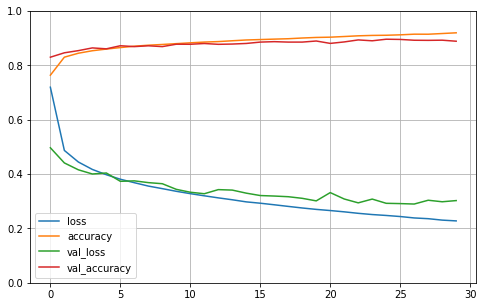

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.show()

In [13]:
model.evaluate(X_test, y_test)

313/313 [==============================] - 1s 4ms/step - loss: 65.8033 - accuracy: 0.8471


[65.80333709716797, 0.847100019454956]

In [14]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

## Regression MLP with Sequential API

In [15]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data,
    housing.target)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full,
    y_train_full
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

In [16]:
model = keras.models.Sequential()

model.add(keras.layers.Dense(30, activation="relu", input_shape=X_train.shape[1:]))
model.add(keras.layers.Dense(1))

model.compile(loss="mean_squared_error", optimizer="sgd")
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))
mse_test = model.evaluate(X_test, y_test)
X_new = X_test[:3]
y_pred = model.predict(X_new)

Epoch 1/20
363/363 [==============================] - 1s 3ms/step - loss: 0.9137 - val_loss: 0.8246
Epoch 2/20
363/363 [==============================] - 1s 2ms/step - loss: 8.0813 - val_loss: 0.6909
Epoch 3/20
363/363 [==============================] - 1s 2ms/step - loss: 0.5262 - val_loss: 0.5922
Epoch 4/20
363/363 [==============================] - 1s 2ms/step - loss: 0.4594 - val_loss: 0.5176
Epoch 5/20
363/363 [==============================] - 1s 2ms/step - loss: 0.4363 - val_loss: 0.4991
Epoch 6/20
363/363 [==============================] - 1s 2ms/step - loss: 0.4280 - val_loss: 0.4837
Epoch 7/20
363/363 [==============================] - 1s 2ms/step - loss: 0.4202 - val_loss: 0.4755
Epoch 8/20
363/363 [==============================] - 1s 2ms/step - loss: 0.4130 - val_loss: 0.4718
Epoch 9/20
363/363 [==============================] - 1s 2ms/step - loss: 0.4102 - val_loss: 0.4717
Epoch 10/20
363/363 [==============================] - 1s 2ms/step - loss: 0.4048 - val_loss: 0.4592

## Functional API

It is used to create unique and custom models. The API works by creating the layers independently and then passing them into the constructor of the subsequent layer.

In [21]:
input_ = keras.layers.Input(shape=X_train.shape[1:])
hidden1 = keras.layers.Dense(30, activation="relu")(input_)
hidden2 = keras.layers.Dense(30, activation="relu")(hidden1)
concat = keras.layers.Concatenate()([input_, hidden2])
output = keras.layers.Dense(1)(concat)
model = keras.Model(inputs=[input_], outputs=[output])

print(model.summary())
# The compilation and fitting to be left for later. Same as before tho.
model.compile(loss="mean_squared_error", optimizer="sgd")
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))
mse_test = model.evaluate(X_test, y_test)
X_new = X_test[:3]
y_pred = model.predict(X_new)

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_4 (InputLayer)           [(None, 8)]          0           []                               
                                                                                                  
 dense_18 (Dense)               (None, 30)           270         ['input_4[0][0]']                
                                                                                                  
 dense_19 (Dense)               (None, 30)           930         ['dense_18[0][0]']               
                                                                                                  
 concatenate_3 (Concatenate)    (None, 38)           0           ['input_4[0][0]',                
                                                                  'dense_19[0][0]']         

## Subclassing API

In [20]:
class WideAndDeepModel(keras.Model):
    def __init__(self, units=30, activation="relu", **kwargs):
        super().__init__(**kwargs)
        self.hidden1 = keras.layers.Dense(units, activation=activation)
        self.hidden2 = keras.layers.Dense(units, activation=activation)
        self.main_output = keras.layers.Dense(1)
        self.auc_output = keras.layers.Dense(1)
    
    def call(self, inputs):
        input_A, input_B = inputs
        hidden1 = self.hidden1(input_B)
        hidden2 = self.hidden2(hidden1)
        concat = keras.layers.concatenate([input_A, hidden_2])
        main_output = self.main_output(concat)
        aux_output = self.aux_output(hidden2)
        return main_output, aux_output
    
model = WideAndDeepModel()

model.compile(loss=["mse", "mse"], loss_weights=[0.9, 0.1], optimizer="sgd")
# Read pg 311 to complete this testing code!
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))
mse_test = model.evaluate(X_test, y_test)
X_new = X_test[:3]
y_pred = model.predict(X_new)

Epoch 1/20


OperatorNotAllowedInGraphError: in user code:

    File "/home/joseaguilar/github/ML-Playground/HOML/venv/lib/python3.8/site-packages/keras/engine/training.py", line 878, in train_function  *
        return step_function(self, iterator)
    File "/home/joseaguilar/github/ML-Playground/HOML/venv/lib/python3.8/site-packages/keras/engine/training.py", line 867, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/home/joseaguilar/github/ML-Playground/HOML/venv/lib/python3.8/site-packages/keras/engine/training.py", line 860, in run_step  **
        outputs = model.train_step(data)
    File "/home/joseaguilar/github/ML-Playground/HOML/venv/lib/python3.8/site-packages/keras/engine/training.py", line 808, in train_step
        y_pred = self(x, training=True)
    File "/home/joseaguilar/github/ML-Playground/HOML/venv/lib/python3.8/site-packages/keras/utils/traceback_utils.py", line 67, in error_handler
        raise e.with_traceback(filtered_t

### Model Saving in tf.Keras

Model saving can be accomplished by simply doing: 

`model.save("keras_model.h5")`. 

This uses the HDF5 format!

The book recomends having a script to train the model and save, and other scripts that load it and use it: 

`model = keras.models.load_model("keras_model.h5")`

Note that this only works with functional and sequential APIs. For subclassing you have to save the weights as well. A method for doing so is shown in HOML 315.